# 學生學習與作業版｜任務 6：相關係數與散布圖

**姓名：**＿戴羽玄＿　**學號／組別：**＿C114118105＿　**完成日期：**＿2026/11/18＿

**學習目標：** 檢查有效配對，以散布圖與相關係數描述線性關係，區分相關與因果。

本單元與教師版「任務 6」相同標題、資料、教學順序與範例；除了明確標示的作業與填空，其餘教師版教材內容保留。對照重點：程式填空對應教師版「6.1 配對」。

### 如何完成
1. 先閱讀觀念與執行資料準備；各單元可以獨立啟動，不需要依賴上一單元的變數。
2. **💻 P 作業**：在指定程式 cell 補上 `____`，可先用提供的 Vibe Coding 提示詞詢問 AI。補完再執行，並執行後面的驗證 cell。未填時出現 `NameError` 是預期現象，先完成填空再繼續。
3. **📝 Q 作業**：查詢 AI、比較教材內容，填寫緊接的文字作答區；請記錄實際提示詞、自己的解釋與查證方式。
4. **🎯 M 小任務**：在任務 4、8、12、16 將前面幾單元整合成可執行的成果。不要只交 AI 回覆，要交實際程式、輸出與自己的解釋。
5. 把 Notebook 存到自己的 Google 雲端硬碟，完成後下載／依教師指示繳交 `.ipynb`；小任務保留輸出、文字與 AI 使用紀錄。

**案例限制：**本資料是公式生成的 60 筆模擬紀錄，不能推論真實學生或因果。缺失與 15 小時值在計分後加入。預測時欄位可得性是假設；全部資料已在前半段探索，後續切出的測試集僅示範流程，不能視為完全獨立的新資料。

**完成檢核：**本單元有 1 項程式填空、2 項 AI 查詢作答；若是任務 4、8、12、16，另外有 1 項整合小任務。請保留自己的輸出、回答和驗證紀錄。


## 共用資料準備
以下在記憶體重建與既有教材相同的資料。執行後可以直接開始本單元；不會覆寫 CSV。


In [1]:
# 匯入套件：numpy 建立隨機資料，pandas 管理表格，pyplot 繪圖
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display

# 固定種子，並維持呼叫順序，以重現原教材的 60 筆模擬資料
rng = np.random.default_rng(42)
n = 60
departments = ["資訊管理", "企業管理", "金融管理"]
# 每個字典鍵是一個欄位；對應的值是 60 名學生的資料
data = {
    "student_id": range(1, n + 1),
    "department": rng.choice(departments, n),
    "sleep_hours": rng.normal(6.7, 1.1, n).round(1),
    "screen_time_hours": rng.normal(5.0, 1.5, n).clip(1, 10).round(1),
    "study_hours": rng.normal(2.5, 1.0, n).clip(0.5, 6).round(1),
    "attendance_rate": rng.normal(88, 8, n).clip(60, 100).round(0),
}
df = pd.DataFrame(data)
# 成績依設定公式與隨機誤差建立；關係來自模擬規則，不能視為因果發現
noise = rng.normal(0, 5, n)
score = (50 + 3 * df["study_hours"] + 2 * df["sleep_hours"]
         - 1.2 * df["screen_time_hours"] + 0.15 * df["attendance_rate"] + noise)
df["quiz_score"] = score.clip(0, 100).round(0)
# 故意在計分後加入資料品質問題；無法從表格還原計分時原始值
df.loc[[5, 17], "sleep_hours"] = np.nan
df.loc[8, "screen_time_hours"] = 15.0
print("模擬資料形狀（列, 欄）：", df.shape)


模擬資料形狀（列, 欄）： (60, 7)


## 6.1 配對與散布圖
散布圖每點是一筆紀錄。先確認兩欄都有效，再觀察方向、形狀和極端點；成績生成公式已使用讀書時間。


## 💻 學生作業 06-P1｜Vibe Coding 程式填空
**對應教師版：**任務 6「6.1 配對」的示範程式。

**任務：**只保留 study_hours 和 quiz_score 都不是缺失值的列，另存 pairs，後續會畫散布圖。

**執行方式：**找到下一個程式儲存格中的 `____`，使用自己撰寫或 AI 建議的程式補齊，保留其他已提供的程式與註解。補完後先執行該 cell，再執行緊接的自動檢查；後續單元內容可能依賴此變數。

**可使用的 Vibe Coding 提示詞：**
```text
我是 Python 與資料分析初學者，正在 Google Colab 使用 pandas、numpy、matplotlib 或 scikit-learn。
我的任務是：只保留 study_hours 和 quiz_score 都不是缺失值的列，另存 pairs，後續會畫散布圖。
請依我貼上的上下文，只協助補上 ____，保留指定變數名稱與後續程式，不修改原始 df。
請解釋每一步的作用，提供繁體中文註解及可手動驗證的方法。
不要虛構執行結果；如需額外資訊，先指出缺少什麼。
```
完成後記錄實際使用的提示詞與自己改動的地方。


有效配對筆數： 60


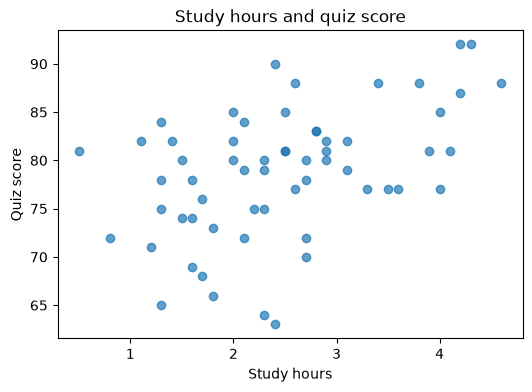

In [2]:
# subset 指定配對欄位；只建立分析副本，保留 df
pairs = df[["study_hours", "quiz_score"]].dropna()  # TODO：建立兩欄皆有效的資料副本
print("有效配對筆數：", len(pairs))
plt.figure(figsize=(6, 4))
plt.scatter(pairs["study_hours"], pairs["quiz_score"], alpha=0.7)
plt.xlabel("Study hours"); plt.ylabel("Quiz score")
plt.title("Study hours and quiz score"); plt.show()


### ✅ 作業 06-P1｜執行驗證
執行下方程式，並同時檢查上方實際輸出。自動檢查只涵蓋主要條件；如果圖表、說明或資料來源不符任務，仍需人工修正。


In [3]:
assert pairs[["study_hours", "quiz_score"]].notna().all().all()
assert len(pairs) == len(df.dropna(subset=["study_hours", "quiz_score"]))
print("檢查通過：有效配對筆數正確。")


檢查通過：有效配對筆數正確。


### ✍️ 作業 06-P1｜我的完成紀錄
- 我實際使用的提示詞（若未使用 AI 請註明）：我是 Python 與資料分析初學者，正在 Google Colab 使用 pandas、numpy、matplotlib 或 scikit-learn。
我的任務是：只保留 study_hours 和 quiz_score 都不是缺失值的列，另存 pairs，後續會畫散布圖。
請依我貼上的上下文，只協助補上 ____，保留指定變數名稱與後續程式，不修改原始 df。
請解釋每一步的作用，提供繁體中文註解及可手動驗證的方法。
不要虛構執行結果；如需額外資訊，先指出缺少什麼。
- 我補上的程式在做什麼：從原始資料表df中選取study_hours和quiz_score這兩個欄位，刪除其中任一欄有缺失值的資料列，將兩欄都有完整數值的有效資料另存為新變數pairs。
- 執行或驗證遇到的問題與修正：執行順利無報錯。
- 檢查結果及我如何確認：執行驗證儲存格後成功印出檢查通過：有效配對筆數正確。上方輸出正常顯示有效配對筆數與Study hours and quiz score散布圖。


## 📝 學生作業 06-Q1｜AI 查詢與作答：相關與因果
**任務：**Pearson 相關係數接近 0，是否代表完全沒有任何關係？為什麼？

**可使用的 AI 提示詞：**
```text
我是 Python 與資料分析初學者。用例子說明 Pearson 係數的方向、線性關係與不能直接推論因果。
請使用繁體中文、台灣常用名詞，分步解釋，並提出我可以自行驗證的一個例子；不要假設我的程式輸出。
```
先閱讀教材，再詢問 AI。請記錄工具名稱、實際提示詞；若 AI 提供資料來源，記錄可查證的網址／文件名稱與日期，並自行檢查，無法查證時寫「尚未查證」。不要提供真實個資。


### ✍️ 作業 06-Q1 專用作答區：請雙擊此文字儲存格填寫
- AI 工具及實際提示詞：Gemini。我是 Python 與資料分析初學者。用例子說明 Pearson 係數的方向、線性關係與不能直接推論因果。
請使用繁體中文、台灣常用名詞，分步解釋，並提出我可以自行驗證的一個例子；不要假設我的程式輸出。
- AI 回答重點（請自行整理）：僅衡量直線趨勢：Pearson相關係數只捕捉變數間的線性關係與正負方向，接近0僅代表無直線關聯。非線性關係會抵銷：若變數呈U型、倒U型等曲線關係，上升段與下降段會在公式中互相抵銷，使係數趨近 0，因此必須搭配散布圖檢查。相關不等於因果：相關係數只能反映數值連動程度，無法證明因果關係。   
- 我的理解與具體例子：Pearson相關係數接近0只代表畫不出一條傾斜的直線來代表趨勢，不代表兩者無關。例如：壓力程度與考試表現常呈倒U型關係：壓力太小沒動力（低分）、適度壓力表現最好（高分）、壓力過大反而失常（低分）；如果直接算兩者的Pearson相關係數會接近0，但其實兩者有很強的曲線關聯。
- 查證來源／方式及日期（無法查證請註明）：Pandas官方文件 pandas.Series.corr https://pandas.pydata.org/docs/reference/api/pandas.Series.corr.html 。2026/11/18
- 我檢查或修正 AI 回答的地方：AI提供了二次曲線的驗證程式，我實際在Colab執行並繪製散布圖確認r=0.0與圖形趨勢的差異，並將解釋重點聚焦回題目核心為何接近0不代表完全沒有關係。


## 6.2 Pearson 相關係數
介於 -1 至 1，正負表示線性方向；接近 0 並不代表一定完全沒有非線性關係，也不能證明因果。


In [4]:
# corr 自動以成對非缺失值計算；額外顯示有效筆數比較透明
for field in ["study_hours", "sleep_hours", "screen_time_hours"]:
    valid = df.dropna(subset=[field, "quiz_score"])
    corr = valid[field].corr(valid["quiz_score"])
    print(field, "配對數：", len(valid), "相關係數：", round(corr, 3))


study_hours 配對數： 60 相關係數： 0.471
sleep_hours 配對數： 58 相關係數： -0.015
screen_time_hours 配對數： 60 相關係數： -0.364


## 📝 學生作業 06-Q2｜AI 查詢與作答：有效配對
**任務：**睡眠有缺失時，分析睡眠與成績為何要先確認有效配對數？

**可使用的 AI 提示詞：**
```text
我是 Python 與資料分析初學者。請以一個欄位有缺失的配對資料說明相關分析的有效配對數及偏差風險。
請使用繁體中文、台灣常用名詞，分步解釋，並提出我可以自行驗證的一個例子；不要假設我的程式輸出。
```
先閱讀教材，再詢問 AI。請記錄工具名稱、實際提示詞；若 AI 提供資料來源，記錄可查證的網址／文件名稱與日期，並自行檢查，無法查證時寫「尚未查證」。不要提供真實個資。


### ✍️ 作業 06-Q2 專用作答區：請雙擊此文字儲存格填寫
- AI 工具及實際提示詞：Gemini。我是 Python 與資料分析初學者。請以一個欄位有缺失的配對資料說明相關分析的有效配對數及偏差風險。
請使用繁體中文、台灣常用名詞，分步解釋，並提出我可以自行驗證的一個例子；不要假設我的程式輸出。
- AI 回答重點（請自行整理）：成對排除機制：相關分析必須兩欄同時有值才能計算，任一欄為NaN該筆資料就會被排除。樣本數過少風險：若某欄大量缺失導致有效配對數過低，相關係數容易受少數極端值左右而失去代表性。選擇性偏差風險：若漏填睡眠時間的人集中在特定族群，留下的有效配對就無法代表全體母體，導致分析結論產生偏差。
- 我的理解與具體例子：分析兩個變數的關聯時，只看總人數沒有意義，必須確認「兩欄同時都有資料」的有效配對數。例如：全班40人都有考試成績，但只有5人填寫睡眠時間，且剛好都是作息規律的高分群；此時若沒先檢查有效配對數只有5筆就直接計算相關係數，就會誤以為全班睡眠與成績呈現高度正相關，其實只是樣本偏誤造成的假象。
- 查證來源／方式及日期（無法查證請註明）：Pandas 官方文件。 pandas.Series.corr https://pandas.pydata.org/docs/reference/api/pandas.Series.corr.html 。2026/11/18
- 我檢查或修正 AI 回答的地方：AI提供了含缺失值的驗證程式，我實際在Colab執行並額外測試valid_pairs篩選前後的.corr()數值是否相同，確認Pandas的自動排除機制確實會讓表面總筆數與實際計算筆數產生落差。


## 6.3 解釋與驗證
**提問：**為什麼睡眠相關的有效筆數較少？為什麼係數方向不保證真實世界因果？
**任務：**選一個欄位畫散布圖；寫趨勢、有效筆數、可能離群點以及資料生成限制。

1.為什麼睡眠相關的有效筆數較少？

因為 sleep_hours欄位本身含有較多缺失值，而程式使用df.dropna(subset=["sleep_hours", "quiz_score"]) 篩選時，必須同時具備睡眠時間與成績的資料列才會保留，因此有效配對筆數會比總人數少。

2.為什麼係數方向不保證真實世界因果？

資料生成限制：本練習的資料是透過程式規則與隨機雜訊模擬生成，並非真實世界透過嚴格控制變因觀測到的生理與學習結果。干擾變數影響：在真實世界中，睡眠與成績同時呈現正相關，可能是受到第三個變數影響，並不代表單純多睡覺就能直接導致成績提高。

3.任務觀察（以 `study_hours` 與 `quiz_score` 為例）：
* **有效筆數**：兩欄皆非缺失的有效配對共有 60 筆。
* **趨勢**：散布圖顯示資料點大致由左下往右上分布，呈現隨讀書時間增加、測驗成績上升的正向線性趨勢，Pearson 相關係數為 0.471。
* **可能離群點**：大部分資料點集中分布，未見極端偏離主群體的離群點，僅少數讀書約3～4小時但成績偏低於70分的個體屬於正常隨機波動。
* **資料生成限制**：本資料集為公式與隨機誤差模擬生成的60筆練習資料，僅反映預設的數學規則，無法推論為真實世界學生的學習因果關係。

## 延伸：看圖與係數是否一致
平均相關係數不能呈現所有資料形狀。請學生比較睡眠與分數的有效配對、散布圖及相關，並指出少數異常值可能改變結果。


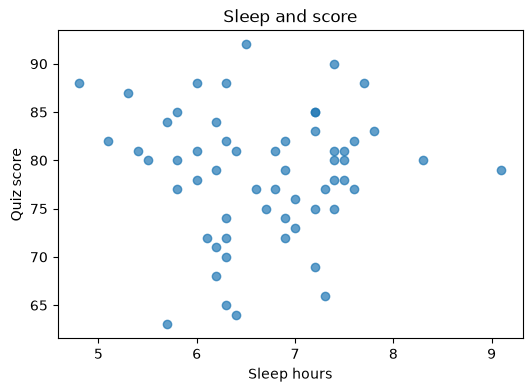

有效筆數： 58
相關係數： -0.015255866695473633


In [7]:
# 建立睡眠／分數有效配對並畫圖；不填補缺失資料
sleep_pairs = df.dropna(subset=["sleep_hours", "quiz_score"])
plt.figure(figsize=(6,4))
plt.scatter(sleep_pairs["sleep_hours"], sleep_pairs["quiz_score"], alpha=0.7)
plt.xlabel("Sleep hours"); plt.ylabel("Quiz score"); plt.title("Sleep and score"); plt.show()
print("有效筆數：", len(sleep_pairs))
print("相關係數：", sleep_pairs["sleep_hours"].corr(sleep_pairs["quiz_score"]))


## 本單元學習收束與 AI 使用紀錄

請學生先用自己的話解釋一個關鍵觀念，再指出一個執行結果及驗證方式。記錄：使用的提示詞、AI 回答中檢查或修改的地方、遇到的問題、修正後的證據與本資料限制。

**通用提示詞**：我是 Python 初學者，請逐步協助我完成上面的任務；每段程式加繁體中文註解，說明輸入、處理與輸出，提供兩項可實際執行的驗證，保留原始資料，不要虛構執行結果。
